In [1]:
%whos
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import fit_lib as fit
import BM29_lib as BM29
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False
from scipy import optimize
from scipy.optimize import curve_fit

who = [
    "BIII_S1",
    "BIII_S2",
    "BIII_S3",
    "BIII_S4",
    "BIII_S5",
]

Interactive namespace is empty.


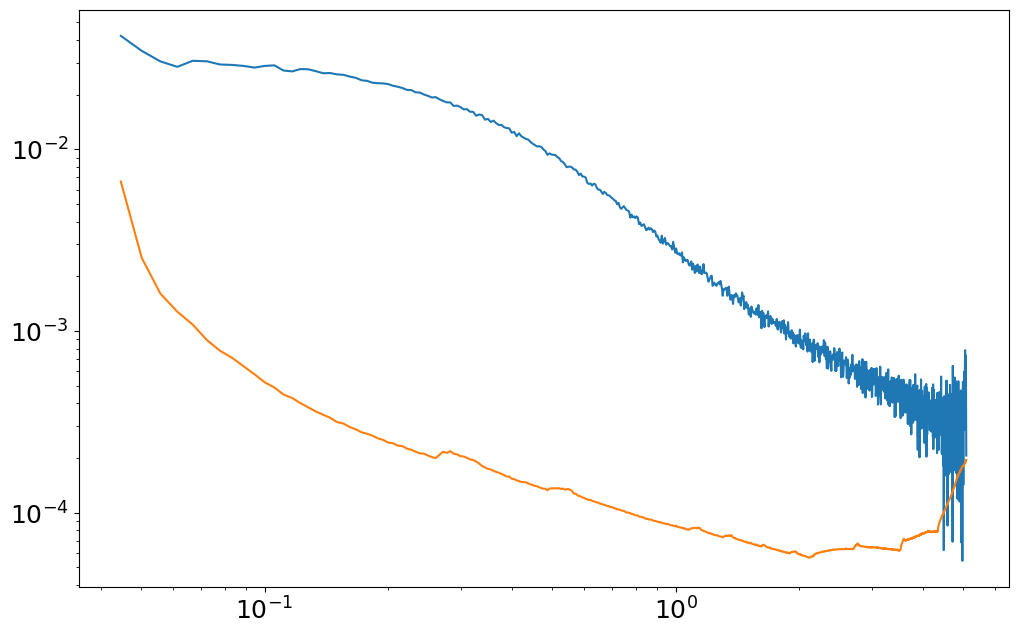

In [2]:
sample = "BIII_S5" 
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)
mask = (q <= 5.1) # & (q >= 0.045)
q    = q[mask]
I    = I[mask]
Ierr = Ierr[mask]

plt.figure(figsize=(12, 7.5))
plt.loglog(q, I)
plt.loglog(q, Ierr)

Guinier fit results for BIII_S5_100uM_aSynE46K:
I(0) = 0.0297 ± 0.00017
Rg   = 4.412 ± 0.039
Check: q_max * Rg = 1.324 (should be < 1.3 for Guinier approximation)


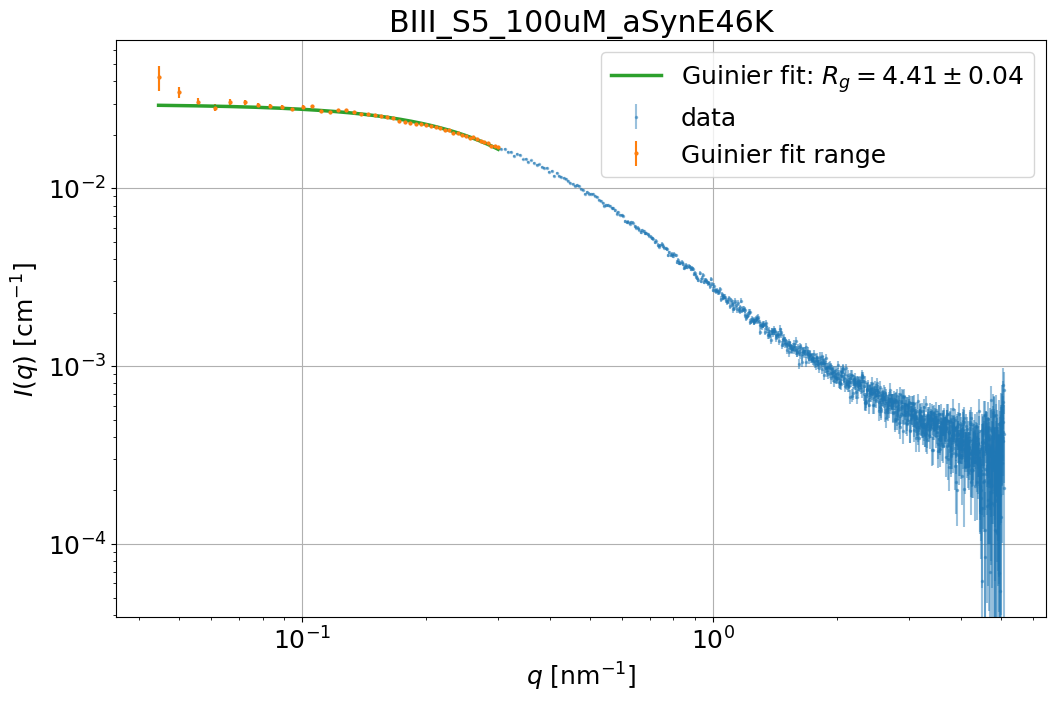

In [3]:
# Adjustable Guinier fit settings
q_min, q_max = 0.0, 0.3
initial_guess = [I[0], 4.0]  # [I0, Rg]
bounds = ([0.0, 0.0], [np.inf, np.inf])

fit_mask = (
    (q >= q_min)
    & (q <= q_max)
)

q_fit = q[fit_mask]
I_fit = I[fit_mask]
Ierr_fit = Ierr[fit_mask]

popt, pcov = optimize.curve_fit(
    fit.guinier_fit,
    q_fit,
    I_fit,
    p0=initial_guess,
    sigma=Ierr_fit,
    bounds=bounds,
    maxfev=10000,
)

I0, Rg = popt
I0_err, Rg_err = np.sqrt(np.diag(pcov))

q_plot = np.linspace(q_fit.min(), q_fit.max(), 500)
I_guinier = fit.guinier_fit(q_plot, *popt)

print(f"Guinier fit results for {BM29.sample_dict[sample]}:")
print(f"I(0) = {I0:.4g} ± {I0_err:.2g}")
print(f"Rg   = {Rg:.3f} ± {Rg_err:.3f}")
print(f"Check: q_max * Rg = {q_max * Rg:.3f} (should be < 1.3 for Guinier approximation)")

plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, yerr=Ierr, fmt=".", ms=3, alpha=0.45, label="data")
plt.errorbar(q_fit, I_fit, yerr=Ierr_fit, fmt=".", ms=4, label="Guinier fit range")
plt.plot(q_plot, I_guinier, lw=2.5, label=fr"Guinier fit: $R_g={Rg:.2f}\pm{Rg_err:.2f}$")

plt.yscale("log")
plt.xscale("log")
plt.xlabel(r"$q$ [nm$^{-1}$]")
plt.ylabel(r"$I(q)$ [cm$^{-1}$]")
plt.title(f"{BM29.sample_dict[sample]}")
plt.legend()
plt.grid()
plt.show()

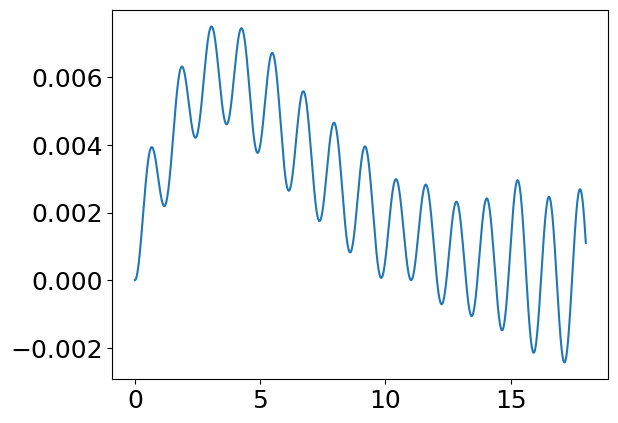

In [12]:
def P(q, I):
    r = np.linspace(0, 18, int(1e+6))
    res = [np.trapezoid(I * q * r_val * np.sin(q * r_val), q) for r_val in r]
    return r, res 

r, P_r = P(q, I)
plt.plot(r, P_r)

In [ ]:
def P_moore(a1, a2, a3, a4, a5, a6, a7, a8, a9, a10, a11, a12, a13, a14, a15, r, Dmax):
    r = np.linspace(0, 100, 1000)
    a = np.array([a1, a2, a3, a4, a5, a6, a7, a8, a9, a10, a11, a12, a13, a14, a15])
    P_res = np.sum([a[i] * np.sin(i * np.pi * r / Dmax) for i in range(len(a))])
    return r, P_res

def fit_P_moore(q, I, Dmax, initial_guess):
    def moore_fit(q, *params):
        r, P_r = P_moore(*params, r=np.linspace(0, Dmax, 1000), Dmax=Dmax)
        return np.interp(q, r, P_r)

    popt, pcov = curve_fit(moore_fit, q, I, p0=initial_guess)
    return popt, pcov

initial_guess = [1.0] * 15  # Initial guess for the 15 parameters
Dmax = 18.0  # Maximum distance for the P(r) function
popt, pcov = fit_P_moore(q, I, Dmax, initial_guess)



[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

Dmax = 15.719160409347943
a = [ 2.08741268e-04  1.25383569e-04  6.24996942e-05  2.36200040e-05
  9.91440155e-06  7.79269566e-06  9.66601839e-07  5.06167674e-06
  3.98164384e-06  2.48861109e-06  3.99349323e-06  3.23424714e-06
  6.03676217e-06 -2.56794818e-06  3.17679400e-05]


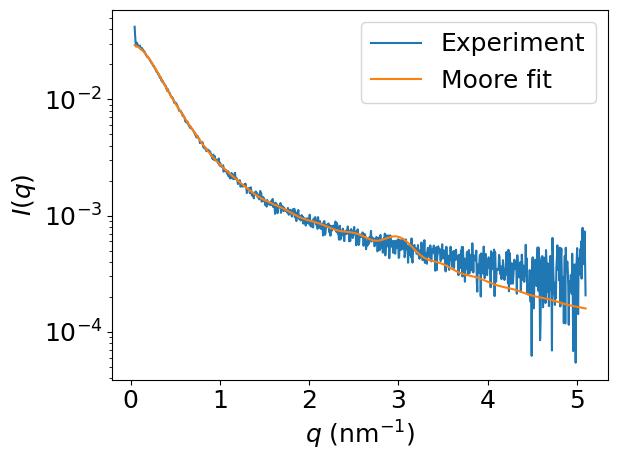

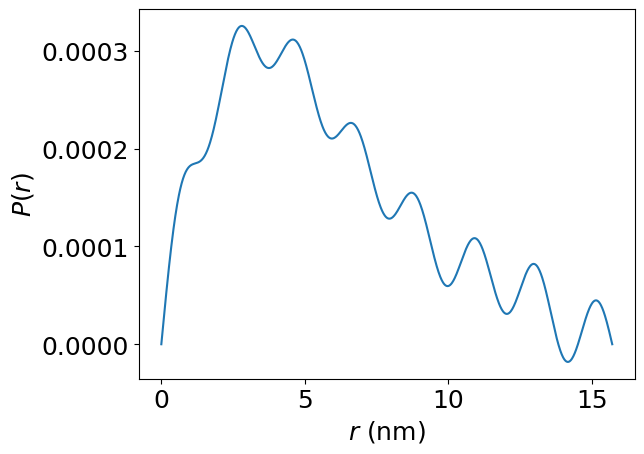

In [15]:
r = np.linspace(0, 18, 1000)

def P_moore(r, Dmax, *a):
    a = np.asarray(a)
    n = np.arange(1, len(a) + 1)

    P = np.sum(
        a[:, None] * np.sin(n[:, None] * np.pi * r[None, :] / Dmax),
        axis=0
    )

    return P

def moore_I(q, Dmax,
            a1, a2, a3, a4, a5,
            a6, a7, a8, a9, a10,
            a11, a12, a13, a14, a15):

    a = np.array([
        a1, a2, a3, a4, a5,
        a6, a7, a8, a9, a10,
        a11, a12, a13, a14, a15
    ])

    n = np.arange(1, 16)

    # P(r)
    P = np.sum(
        a[:, None] *
        np.sin(n[:, None] * np.pi * r[None, :] / Dmax),
        axis=0
    )

    # P(r) -> I(q)
    qr = q[:, None] * r[None, :]
    kernel = np.sinc(qr / np.pi)

    I = 4 * np.pi * np.trapezoid(
        P[None, :] * kernel,
        r,
        axis=1
    )

    return I

p0 = [
    17,          # Dmax
    1, 1, 1, 1, 1,
    1, 1, 1, 1, 1,
    1, 1, 1, 1, 1
]

popt, pcov = curve_fit(
    moore_I,
    q,
    I,
    p0=p0,
    sigma=Ierr,
    absolute_sigma=True,
    maxfev=10000
)

Dmax_fit = popt[0]
a_fit = popt[1:]

print("Dmax =", Dmax_fit)
print("a =", a_fit)

r = np.linspace(0, Dmax_fit, 1000)

P_fit = P_moore(
    r,
    Dmax_fit,
    *a_fit
)

I_fit = moore_I(q, Dmax_fit, *a_fit)

import matplotlib.pyplot as plt

plt.figure()
plt.plot(q, I, label="Experiment")
plt.plot(q, I_fit, label="Moore fit")
plt.yscale("log")
plt.xlabel(r"$q$ (nm$^{-1}$)")
plt.ylabel(r"$I(q)$")
plt.legend()


plt.figure()
plt.plot(r, P_fit)
plt.xlabel(r"$r$ (nm)")
plt.ylabel(r"$P(r)$")
plt.show()